# GROUP_02 — Hip fracture among adult women (C2)


**Library requirements:** pandas, numpy, matplotlib, pyarrow (or fastparquet, to read the parquet).
Install with `pip install pandas numpy matplotlib pyarrow`.

**Run instructions:** place `grd_procesado.parquet` in `./data/` relative to this notebook, then
Restart Kernel and Run All, top to bottom, before submission.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#DATA_PATH = Path('./data/grd_procesado.parquet')  # project-relative, not a personal path
DATA_PATH = Path('/Users/maria/Documents/Business Intehlligence/W1/grd_procesado.parquet')

## 1. Load data and initial inspection

In [4]:
df = pd.read_parquet(DATA_PATH)  # original, never modified downstream
print('Shape:', df.shape)
df.head()

Shape: (367895, 52)


,COD_ESTABLECIMIENTO,CIP_ENCRIPTADO,SEXO,FECHA_NACIMIENTO,PROVINCIA,COMUNA_REGISTRADA,PREVISION,SERVICIO_SALUD,TIPO_PROCEDENCIA,TIPO_INGRESO,...,CAMAS_CRITICAS,POB_MULT_ESTAB,COMUNA_CON_ESTAB_AC,FALLECIDO,CRITICAS_PROP,CAMAS_COMUNA,CRITICAS_COMUNA,CAMAS_1000HAB,CRITICAS_1000HAB,TASA_MORTALIDAD_COMUNA
0,118100,467373,HOMBRE,1969-09-10,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) B,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
1,118100,562854,HOMBRE,1956-02-07,CONCEPCION,CORONEL,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,1,0,0.128118,882,113,3.717488,0.476277,0.117963
2,118100,199980,MUJER,1960-02-28,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,APS CONSULTORIO (CESFAM),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
3,118100,857926,MUJER,1933-01-12,CONCEPCION,CHIGUAYANTE,FONASA INSTITUCIONAL - (MAI) D,CONCEPCIÓN,"OTRAS INSTITUCIONES SALUD (CLÍNICAS PRIVADAS, ...",URGENCIA,...,113,0.090303,0,1,0.128118,882,113,3.717488,0.476277,0.117963
4,118100,284629,HOMBRE,1951-05-03,CURICO,TENO,FONASA INSTITUCIONAL - (MAI) C,DEL MAULE,"CENTRO ESPECIALIDADES (CDT, CRS, CONSULTORIO A...",PROGRAMADA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963


In [5]:
print('Nulls per column:')
print(df.isnull().sum())

Nulls per column:
COD_ESTABLECIMIENTO          0
CIP_ENCRIPTADO               0
SEXO                         0
FECHA_NACIMIENTO             0
PROVINCIA                    0
COMUNA_REGISTRADA            0
PREVISION                    0
SERVICIO_SALUD               0
TIPO_PROCEDENCIA             0
TIPO_INGRESO                 0
FECHA_INGRESO                0
FECHAALTA                    0
TIPOALTA                     0
DIAGNOSTICO1                 0
DIAGNOSTICO2                 9
DIAGNOSTICO3              4920
PROCEDIMIENTO1             127
PROCEDIMIENTO2            2329
IR_29301_COD_GRD             0
IR_29301_PESO                0
IR_29301_SEVERIDAD           0
IR_29301_MORTALIDAD          0
YEAR                         0
EDAD                         0
DIAS_ESTANCIA                0
N_COMORBILIDADES             0
N_PROCEDIMIENTOS             0
INDICE_CHARLSON              0
DESCRIPCION                  0
SECCION                      0
COD_REGION                   0
REGION               

In [6]:
print(df['COMPLEJIDAD_ESTAB'].value_counts(dropna=False))
print()
print(df['SEXO'].value_counts(dropna=False))
print()
print(df['EDAD'].describe())
print()
print(df['YEAR'].value_counts().sort_index())

COMPLEJIDAD_ESTAB
Alta Complejidad       358743
Mediana Complejidad      9152
Baja Complejidad            0
No Aplica                   0
Pendiente                   0
Name: count, dtype: int64

SEXO
HOMBRE         213422
MUJER          154431
DESCONOCIDO        42
Name: count, dtype: int64

count    367895.000000
mean         50.987017
std          26.229025
min           0.000000
25%          34.500000
50%          58.400000
75%          70.800000
max         108.200000
Name: EDAD, dtype: float64

YEAR
2019    50135
2020    54370
2021    67748
2022    61547
2023    66717
2024    67378
Name: count, dtype: int64


## 2. Upstream data provenance
The parquet arrives already selected/enriched (joined commune-level fields). COMPLEJIDAD_ESTAB includes both high- and medium-complexity establishments (see Section 1 value counts), this analysis does not restrict to high-complexity hospitals only.

In [7]:
print('Total rows as delivered:', len(df))
print('Columns already present (pre-joined/derived):', list(df.columns))


Total rows as delivered: 367895
Columns already present (pre-joined/derived): ['COD_ESTABLECIMIENTO', 'CIP_ENCRIPTADO', 'SEXO', 'FECHA_NACIMIENTO', 'PROVINCIA', 'COMUNA_REGISTRADA', 'PREVISION', 'SERVICIO_SALUD', 'TIPO_PROCEDENCIA', 'TIPO_INGRESO', 'FECHA_INGRESO', 'FECHAALTA', 'TIPOALTA', 'DIAGNOSTICO1', 'DIAGNOSTICO2', 'DIAGNOSTICO3', 'PROCEDIMIENTO1', 'PROCEDIMIENTO2', 'IR_29301_COD_GRD', 'IR_29301_PESO', 'IR_29301_SEVERIDAD', 'IR_29301_MORTALIDAD', 'YEAR', 'EDAD', 'DIAS_ESTANCIA', 'N_COMORBILIDADES', 'N_PROCEDIMIENTOS', 'INDICE_CHARLSON', 'DESCRIPCION', 'SECCION', 'COD_REGION', 'REGION', 'ESTABLECIMIENTO', 'COD_COMUNA', 'COMUNA_ESTAB', 'LATITUD', 'LONGITUD', 'PRESTADOR', 'COMPLEJIDAD_ESTAB', 'POB_COMUNA', 'POB_REGION', 'CAMAS_TOTALES', 'CAMAS_CRITICAS', 'POB_MULT_ESTAB', 'COMUNA_CON_ESTAB_AC', 'FALLECIDO', 'CRITICAS_PROP', 'CAMAS_COMUNA', 'CRITICAS_COMUNA', 'CAMAS_1000HAB', 'CRITICAS_1000HAB', 'TASA_MORTALIDAD_COMUNA']


**2024 completeness check** (pending item from C1 feedback — confirm the last year isn't
truncated before using it in year-over-year comparisons).

In [8]:
df['FECHAALTA'] = pd.to_datetime(df['FECHAALTA'], errors='coerce')  # adjust column name if different
monthly = df['FECHAALTA'].dt.to_period('M').value_counts().sort_index()
print(monthly.tail(18))

FECHAALTA
2023-07    5899
2023-08    5927
2023-09    5447
2023-10    5666
2023-11    5608
2023-12    5493
2024-01    5751
2024-02    5434
2024-03    5623
2024-04    5920
2024-05    6141
2024-06    5855
2024-07    6308
2024-08    6343
2024-09    5615
2024-10    6463
2024-11    5880
2024-12    6004
Freq: M, Name: count, dtype: int64


## 3. Data quality checks
Four distinct checks: duplicates, missing values, invalid values, recorded periods.

### 3.1 Duplicate records

In [9]:
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print('Rows involved in duplication:', dups.shape[0])
print('Exact duplicate rows (duplicated()):', df.duplicated().sum())
print(f"Percentage: {df.duplicated().sum()/len(df)*100:.3f}%")

Rows involved in duplication: 210
Exact duplicate rows (duplicated()): 105
Percentage: 0.029%


In [10]:
# Which year the duplicates concentrate in
df.groupby('YEAR').apply(lambda x: x.duplicated().sum())

YEAR
2019      2
2020    103
2021      0
2022      0
2023      0
2024      0
dtype: int64

In [11]:
# Inspect a sample: same diagnosis/age/sex/year confirms these are not distinct episodes
dups[['CIP_ENCRIPTADO','DESCRIPCION','EDAD','SEXO','YEAR']].head(20)

,CIP_ENCRIPTADO,DESCRIPCION,EDAD,SEXO,YEAR
82540,612841,"COVID-19, virus identificado",63.5,MUJER,2020
83545,612841,"COVID-19, virus identificado",63.5,MUJER,2020
48828,233609,"Traumatismo del intestino delgado, con herida ...",14.8,HOMBRE,2020
90463,233609,"Traumatismo del intestino delgado, con herida ...",14.8,HOMBRE,2020
68585,397419,"Fractura del cuello de fémur, cerrada",89.6,HOMBRE,2020
72968,397419,"Fractura del cuello de fémur, cerrada",89.6,HOMBRE,2020
47221,931293,"Hemorragia intracerebral en hemisferio, cortical",53.5,HOMBRE,2020
73457,931293,"Hemorragia intracerebral en hemisferio, cortical",53.5,HOMBRE,2020
48473,1332239,"Esclerosis sistémica, no especificada",41.0,MUJER,2020
85805,1332239,"Esclerosis sistémica, no especificada",41.0,MUJER,2020


**Rule:** a row is a duplicate if every field matches another row exactly.
**Result:** see counts above (105 rows, ~0.03%, concentrated in 2020).
**Meaning:** matching derived/joined fields rules out genuine re-admission; most likely a 2020
reprocessing artifact.
**Action:** drop exact duplicates; keep all other rows unchanged.

In [12]:
df_clean = df.drop_duplicates().copy()
print('Rows before:', len(df), '| Rows after:', len(df_clean))

Rows before: 367895 | Rows after: 367790


### 3.2 Missing values (beyond the isnull() count above)

In [13]:
# Placeholder codes that hide missingness without appearing as NaN
for c in ['CIP_ENCRIPTADO', 'DIAGNOSTICO1', 'SEXO']:
    if c in df_clean.columns:
        flagged = df_clean[c].isin(['SIN INFORMACIÓN', 'DESCONOCIDO'])
        print(c, '-> placeholder count:', flagged.sum())

CIP_ENCRIPTADO -> placeholder count: 654
DIAGNOSTICO1 -> placeholder count: 0
SEXO -> placeholder count: 42


### 3.3 Invalid values

In [14]:
invalid_age = df_clean[(df_clean['EDAD'] < 0) | (df_clean['EDAD'] > 110)]
print('Rows with EDAD outside [0, 110]:', len(invalid_age))

Rows with EDAD outside [0, 110]: 0


### 3.4 Recorded periods

In [15]:
number_of_establishments_by_year = (
    df_clean.groupby('YEAR')['ESTABLECIMIENTO']
    .nunique()
    .reset_index()
    .rename(columns={'ESTABLECIMIENTO': 'num_establishments'})
)
number_of_establishments_by_year

,YEAR,num_establishments
0,2019,65
1,2020,65
2,2021,65
3,2022,68
4,2023,70
5,2024,72


## 4. Variable dictionary (key fields used below)

| Field | Meaning | Unit / codes | Missing means |
|---|---|---|---|
| `SEXO` | Patient sex | MUJER / HOMBRE | not observed in this data |
| `EDAD` | Age at admission | years | n/a (0% missing) |
| `DIAGNOSTICO1` | Primary diagnosis, ICD-10 | code, e.g. S72.00 | n/a |
| `DESCRIPCION` | Primary diagnosis, free text | text | n/a |
| `DIAS_ESTANCIA` | Length of stay | days | n/a |
| `FALLECIDO` | Died during this episode | 0/1 | not observed |
| `TIPOALTA` | Discharge destination | category | n/a |
| `IR_29301_SEVERIDAD` | GRD severity category | ordinal | n/a |
| `INDICE_CHARLSON` | Comorbidity index | numeric | n/a |
| `N_COMORBILIDADES` | Comorbidity count | integer | n/a |
| `COMUNA_ESTAB` | Hospital's commune | text | n/a |
| `COMUNA_REGISTRADA` | Patient's registered commune | text | n/a |
| `CIP_ENCRIPTADO` | Encrypted patient identifier | hash | placeholder values possible (see 3.2) |



## 5. Build the analysis population
All downstream cells use `mujeres` (adult women) and `hip` (hip-fracture subset). Both are
defined here, once, before any cell that uses them (fixes the C1 execution-order issue).

In [16]:
bins   = [18, 30, 45, 60, 75, 90, 111]
labels = ['18-29', '30-44', '45-59', '60-74', '75-89', '90+']
YEARS  = range(2019, 2025)

mujeres = df_clean[(df_clean['SEXO'] == 'MUJER') &
                    (df_clean['EDAD'] >= 18) &
                    (df_clean['YEAR'].isin(YEARS))].copy()
mujeres['GRUPO_ETARIO'] = pd.cut(mujeres['EDAD'], bins=bins, labels=labels, right=False)

hip_codes = ['Fractura del cuello de fémur, cerrada', 'Fractura pertrocanteriana, cerrada']
hip = mujeres[mujeres['DESCRIPCION'].isin(hip_codes)].copy()

hombres = df_clean[(df_clean['SEXO'] == 'HOMBRE') &
                    (df_clean['EDAD'] >= 18) &
                    (df_clean['YEAR'].isin(YEARS))].copy()
hip_m = hombres[hombres['DESCRIPCION'].isin(hip_codes)].copy()

print('mujeres:', len(mujeres), '| hip (women):', len(hip), '| hip (men):', len(hip_m))

mujeres: 127220 | hip (women): 4361 | hip (men): 1677


### 5.1 Validate the hip-fracture cohort against ICD-10 codes

In [17]:
codigos_reales = mujeres.loc[mujeres['DESCRIPCION'].isin(hip_codes), 'DIAGNOSTICO1'].unique()
print('ICD-10 codes found for these DESCRIPCION values:', codigos_reales)

hip2 = mujeres[mujeres['DIAGNOSTICO1'].isin(codigos_reales)].copy()
print('hip (by description):', len(hip), '| hip2 (by ICD-10 code):', len(hip2))
print('Cohorts match:', set(hip['CIP_ENCRIPTADO']) == set(hip2['CIP_ENCRIPTADO']))

ICD-10 codes found for these DESCRIPCION values: <StringArray>
['S72.00', 'S72.10']
Length: 2, dtype: string
hip (by description): 4361 | hip2 (by ICD-10 code): 4361
Cohorts match: True


### 5.2 Filter waterfall (row counts at each stage)

In [18]:
waterfall = pd.DataFrame({
    'step': ['Full dataset', 'Deduplicated', 'Adult women, study years', 'Hip fracture subset'],
    'rows': [len(df), len(df_clean), len(mujeres), len(hip)]
})
waterfall['pct_of_original'] = waterfall['rows'] / len(df) * 100
waterfall

,step,rows,pct_of_original
0,Full dataset,367895,100.000000
1,Deduplicated,367790,99.971459
2,"Adult women, study years",127220,34.580519
3,Hip fracture subset,4361,1.185393


## 6. Data checks and limits (Five Cs)

### 6.1 Conformed — commune-level fields (CORRECTED to match the report's description)
C1 feedback: the report described a commune-**year** check, but the code only grouped by
commune. Fixed below.

In [19]:
key_by_estab      = df.groupby('COMUNA_ESTAB')['POB_COMUNA'].nunique().max()
key_by_estab_year  = df.groupby(['COMUNA_ESTAB', 'YEAR'])['POB_COMUNA'].nunique().max()
key_by_reg         = df.groupby('COMUNA_REGISTRADA')['POB_COMUNA'].nunique().max()

print('Keyed on COMUNA_ESTAB alone:', key_by_estab)
print('Keyed on (COMUNA_ESTAB, YEAR):', key_by_estab_year)   # should be 1 if population is annual
print('Keyed on COMUNA_REGISTRADA:', key_by_reg)

pct_diff = (df['COMUNA_REGISTRADA'] != df['COMUNA_ESTAB']).mean() * 100
print(f'Registered != establishment commune: {pct_diff:.1f}%')

Keyed on COMUNA_ESTAB alone: 6
Keyed on (COMUNA_ESTAB, YEAR): 1
Keyed on COMUNA_REGISTRADA: 200
Registered != establishment commune: 57.2%


/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_85468/4169676358.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  key_by_reg         = df.groupby('COMUNA_REGISTRADA')['POB_COMUNA'].nunique().max()


### 6.2 Consistent — severity coding stability by year
Note: similar distributions are *consistent with* unchanged coding, not proof of it (C1 feedback).

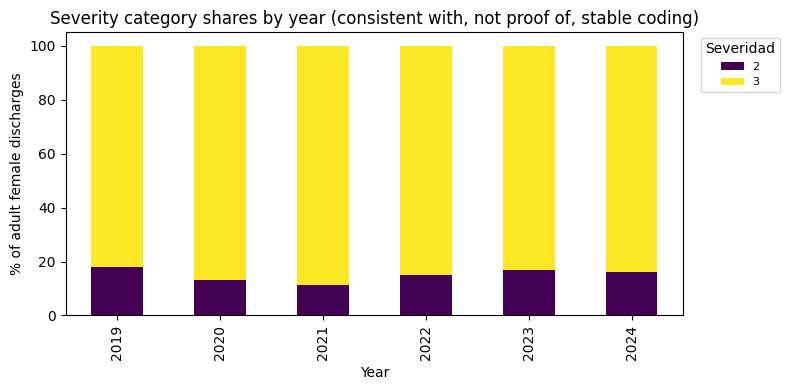

In [20]:
sev_anual = (mujeres.groupby(['YEAR', 'IR_29301_SEVERIDAD'], observed=True)
             .size().unstack().apply(lambda r: r / r.sum() * 100, axis=1))

fig, ax = plt.subplots(figsize=(8, 4))
sev_anual.plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_ylabel('% of adult female discharges')
ax.set_xlabel('Year')
ax.set_title('Severity category shares by year (consistent with, not proof of, stable coding)')
ax.legend(title='Severidad', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 6.3 Establishment growth, normalized (adult women only).

In [23]:
anual = mujeres.groupby('YEAR').agg(
    total=('SEXO', 'size'),
    mujeres=('SEXO', 'size')  # already filtered to MUJER
)
n_estab = number_of_establishments_by_year.set_index('YEAR')['num_establishments']
anual['discharges_per_estab'] = anual['mujeres'] / n_estab
anual

,total,mujeres,discharges_per_estab
YEAR,,,
2019,17064,17064,262.523077
2020,17943,17943,276.046154
2021,23825,23825,366.538462
2022,21204,21204,311.823529
2023,22979,22979,328.271429
2024,24205,24205,336.180556


A constant number of hospitals does not prove the same hospitals and cases were represented each year it only rules out reporting-coverage growth as the explanation. The observed home-hospitalization rise (7.0%→23.3%, Section 7.2) is reported as an observed change, not as one with facility-composition effects definitively ruled out.

## 7. Exploratory analysis

### 7.1 Distribution — length of stay, adult women

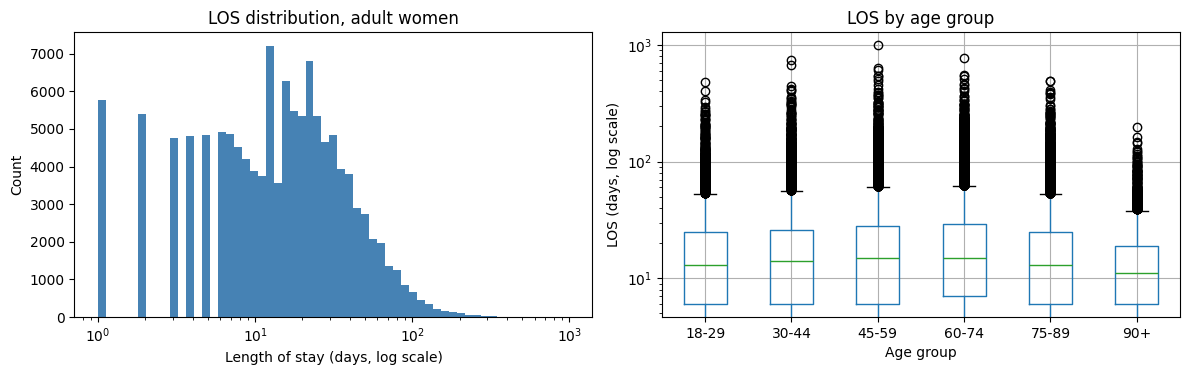

In [25]:
los_pos = mujeres.loc[mujeres['DIAS_ESTANCIA'] > 0, 'DIAS_ESTANCIA']
log_bins = np.logspace(np.log10(los_pos.min()), np.log10(los_pos.max()), 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(los_pos, bins=log_bins, color='steelblue')
axes[0].set_xscale('log')
axes[0].set_xlabel('Length of stay (days, log scale)')
axes[0].set_ylabel('Count')
axes[0].set_title('LOS distribution, adult women')

mujeres.boxplot(column='DIAS_ESTANCIA', by='GRUPO_ETARIO', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_xlabel('Age group')
axes[1].set_ylabel('LOS (days, log scale)')
axes[1].set_title('LOS by age group')
plt.suptitle('')
plt.tight_layout()
plt.show()

### 7.2 Comparison — discharge destination by age group AND by year (corrected scope)
C1 feedback: the claim that home hospitalization *increased over time* and *caused* shorter
stays went beyond what was shown. This cell tests the time dimension directly instead of
assuming it.

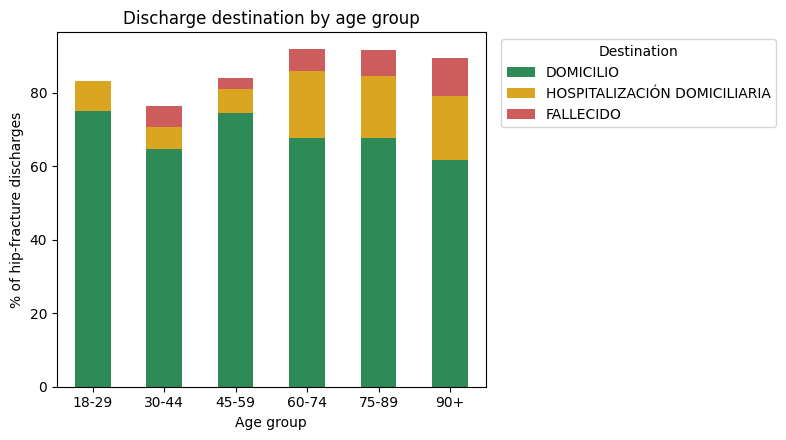

In [26]:
dest_by_age = pd.crosstab(hip['GRUPO_ETARIO'], hip['TIPOALTA'], normalize='index') * 100
keep = ['DOMICILIO', 'HOSPITALIZACIÓN DOMICILIARIA', 'FALLECIDO']

fig, ax = plt.subplots(figsize=(8, 4.5))
dest_by_age[keep].plot(kind='bar', stacked=True, ax=ax, color=['seagreen', 'goldenrod', 'indianred'])
ax.set_ylabel('% of hip-fracture discharges')
ax.set_xlabel('Age group')
ax.set_title('Discharge destination by age group')
ax.legend(title='Destination', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

TIPOALTA  DOMICILIO  HOSPITALIZACIÓN DOMICILIARIA  FALLECIDO
YEAR                                                        
2019      75.233645                      7.009346   8.411215
2020      65.975104                     10.788382  13.278008
2021      65.000000                     16.774194   9.032258
2022      67.833698                     16.192560   7.111597
2023      64.712042                     19.685864   6.806283
2024      63.201663                     23.284823   4.885655


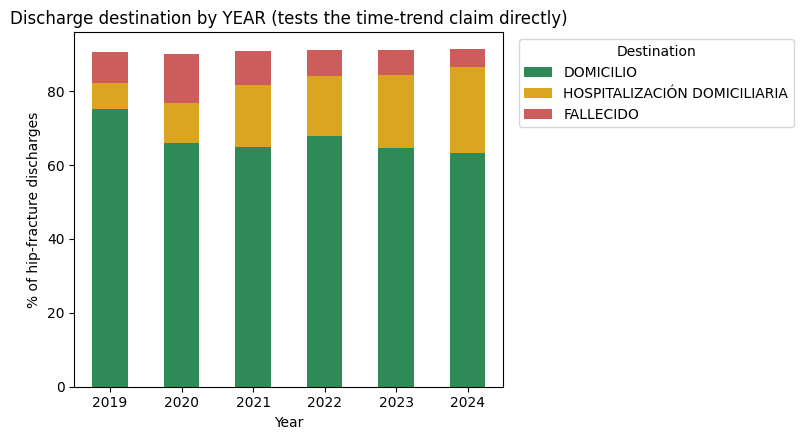

TIPOALTA                                       FALLECIDO
ALTA VOLUNTARIA                                0            18.0
DERIVACIÓN A OTROS CENTROS (CÁRCEL, HOGAR DE   0            12.0
DERIVACIÓN INST. PRIVADA (COMPRA DE SERVICIOS  0            17.0
DERIVACIÓN INST. PRIVADA (VOLUNTARIO)          0             7.5
DERIVACIÓN OTRO HOSPITAL DE LA RED NACIONAL    0            15.0
DERIVACIÓN OTRO HOSPITAL DEL SERVICIO          0            17.0
DOMICILIO                                      0            13.0
FALLECIDO                                      1            16.0
FUGA DEL PACIENTE                              0            15.0
HOSPITALIZACIÓN DOMICILIARIA                   0            13.0
Name: DIAS_ESTANCIA, dtype: float64


In [27]:
dest_by_year = pd.crosstab(hip['YEAR'], hip['TIPOALTA'], normalize='index') * 100
print(dest_by_year[keep])

fig, ax = plt.subplots(figsize=(8, 4.5))
dest_by_year[keep].plot(kind='bar', stacked=True, ax=ax, color=['seagreen', 'goldenrod', 'indianred'])
ax.set_ylabel('% of hip-fracture discharges')
ax.set_xlabel('Year')
ax.set_title('Discharge destination by YEAR (tests the time-trend claim directly)')
ax.legend(title='Destination', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# LOS within destination and survival groups, before recommending capacity changes
print(hip.groupby(['TIPOALTA', 'FALLECIDO'], observed=True)['DIAS_ESTANCIA'].median())

### 7.3 Another useful view — comorbidity-adjusted mortality

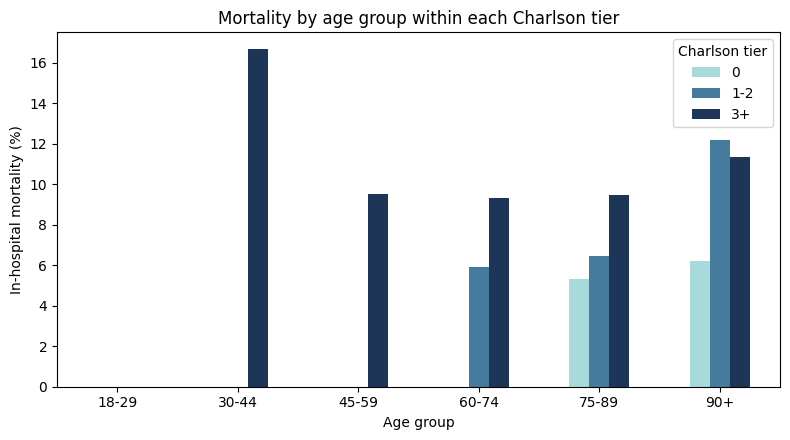

Note: this concerns MORTALITY, not an adjusted change in discharge destination (C1 feedback).


In [28]:
hip['CHARLSON_TIER'] = pd.cut(hip['INDICE_CHARLSON'], bins=[-1, 0, 2, 100], labels=['0', '1-2', '3+'])
tier_mort = pd.crosstab(hip['GRUPO_ETARIO'], hip['CHARLSON_TIER'], values=hip['FALLECIDO'], aggfunc='mean') * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
tier_mort.plot(kind='bar', ax=ax, color=['#a8dadc', '#457b9d', '#1d3557'])
ax.set_ylabel('In-hospital mortality (%)')
ax.set_xlabel('Age group')
ax.set_title('Mortality by age group within each Charlson tier')
ax.legend(title='Charlson tier')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print('Note: this concerns MORTALITY, not an adjusted change in discharge destination (C1 feedback).')

### 7.4 Supporting — mortality by year, and sex comparison

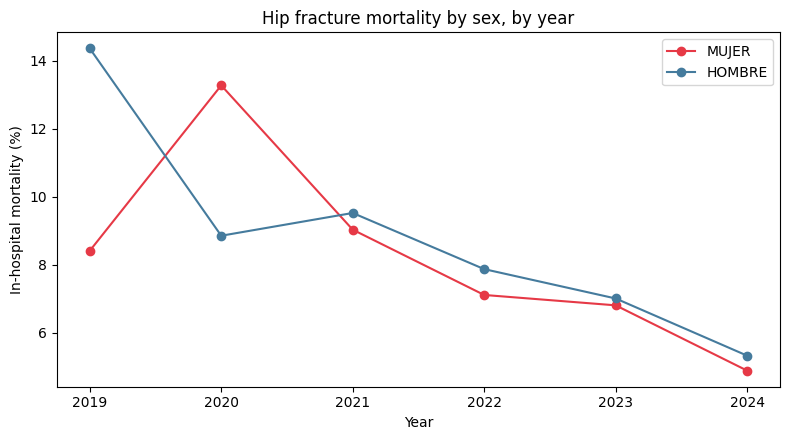

      n_mujer  n_hombre
YEAR                   
2019      428       181
2020      482       192
2021      620       252
2022      914       343
2023      955       371
2024      962       338


In [29]:
mort_year = hip.groupby('YEAR', observed=True).agg(n=('FALLECIDO', 'size'), mortalidad=('FALLECIDO', 'mean'))

mort_year_sex = pd.concat([
    hip.groupby('YEAR', observed=True)['FALLECIDO'].mean().rename('MUJER'),
    hip_m.groupby('YEAR', observed=True)['FALLECIDO'].mean().rename('HOMBRE')
], axis=1) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
mort_year_sex.plot(marker='o', ax=ax, color=['#e63946', '#457b9d'])
ax.set_ylabel('In-hospital mortality (%)')
ax.set_xlabel('Year')
ax.set_title('Hip fracture mortality by sex, by year')
plt.tight_layout()
plt.show()

n_sex = pd.concat([
    hip.groupby('YEAR', observed=True).size().rename('n_mujer'),
    hip_m.groupby('YEAR', observed=True).size().rename('n_hombre')
], axis=1)
print(n_sex)

## 8. Check for data leakage
Intended decision: at **admission**, classify a hip-fracture patient's likely length-of-stay /
mortality risk to plan post-acute capacity. Only information available *at admission* may be
used as an input.

| Risk | Status | Evidence | Action |
|---|---|---|---|
| **Information from the future** | Present | `TIPOALTA`, `FALLECIDO`, `DIAS_ESTANCIA` are only known at/after discharge | Excluded from any future model's inputs; only admission-time fields (age, severity, comorbidity count, admission type) proposed as inputs |
| **An input that gives away the answer** | Present | Using `DIAS_ESTANCIA` to predict a "prolonged stay" label would directly reveal the answer | Target variable (if LOS-based) must be derived from `DIAS_ESTANCIA` and then that column excluded from inputs |
| **Related records crossing the split** | Present | Some `CIP_ENCRIPTADO` values have multiple discharges (not validated as readmissions — see Clean) | Split is time-based (by YEAR), not row-random, which limits but does not fully eliminate this; flagged as a residual risk below |
| **Preparation learned from reserved data** | Not yet applicable in this notebook | No transformation has been fit yet | Addressed directly in Section 10, where the median/encoding is learned on the training split only |

Excluded from any future model’s inputs: TIPOALTA, FALLECIDO, DIAS_ESTANCIA. Proposed as inputs, confirmed admission-safe: age, admission type (TIPO_INGRESO). Proposed only conditionally: severity (IR_29301_SEVERIDAD) and comorbidity index (INDICE_CHARLSON) — their availability at admission is unconfirmed (see note below); they are not used unless and until this is resolved.

In [30]:
# Residual risk check: how many patients have more than one hip-fracture discharge
# in this cohort (relevant to "related records crossing the split")
repeat_patients = hip['CIP_ENCRIPTADO'].value_counts()
print('Patients with >1 hip-fracture discharge in this cohort:', (repeat_patients > 1).sum())

Patients with >1 hip-fracture discharge in this cohort: 25


## 9. Separate the data and demonstrate preparation
No model is trained or scored here (not required for W2) — only the split, validation route,
and one training-only transformation.

**Split choice:** time-based, not random — matches the intended prospective use (classify a
*future* admission), and keeps the full study period's coding/establishment changes from mixing
test-period information into training.

The reserved test years (2023–2024) were already examined descriptively in this notebook’s EDA (Sections 6–7, e.g., severity-by-year, destination-by-year). This is disclosed here: test is not an entirely unseen set in the sense of never having been looked at, though no modeling choice in Section 9 onward was fit or tuned using it.

In [31]:
train = hip[hip['YEAR'].isin([2019, 2020, 2021, 2022])].copy()
test  = hip[hip['YEAR'].isin([2023, 2024])].copy()

print('Train rows:', len(train), '| Test rows:', len(test))

# Overlap check: do any patients appear in both train and test?
overlap = set(train['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
print('Patients appearing in both train and test:', len(overlap))

Train rows: 2444 | Test rows: 1917
Patients appearing in both train and test: 10


In [32]:
train['CIP_ENCRIPTADO'].nunique()

2436

In [33]:
test['CIP_ENCRIPTADO'].nunique()

1910

In [34]:
print(train['CIP_ENCRIPTADO'].nunique() + test['CIP_ENCRIPTADO'].nunique())

4346


**Internal validation route:** a validation subset carved out of the training years (not from
test), used to compare preparation choices before any final evaluation.

In [35]:
train_fit = train[train['YEAR'].isin([2019, 2020, 2021])].copy()
train_val = train[train['YEAR'] == 2022].copy()

print('Train-fit rows:', len(train_fit), '| Train-val rows:', len(train_val), '| Test rows:', len(test))

Train-fit rows: 1530 | Train-val rows: 914 | Test rows: 1917


Overlap Checks: 

In [37]:
overlap_fit_val = set(train_fit['CIP_ENCRIPTADO']) & set(train_val['CIP_ENCRIPTADO'])
overlap_val_test = set(train_val['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
print('Patients in both train_fit and train_val:', len(overlap_fit_val))
print('Patients in both train_val and test:', len(overlap_val_test))

Patients in both train_fit and train_val: 5
Patients in both train_val and test: 7


Since CIP_ENCRIPTADO is not validated as a unique-episode identifier (see Clean), a patient treated in train_fit/train_val could reappear with a later hip fracture in test; this is a distinct new episode, not a leak of the same outcome, but it means test performance may be modestly optimistic for any patient the model has implicitly seen before through shared individual-level patterns (e.g., baseline frailty).

### 9.1 One training-only transformation
Filling missing `INDICE_CHARLSON` values using the median learned **only** from `train_fit`,
then applying that same fixed value to validation and test without recalculating it there.

In [36]:
# One-hot encode TIPO_INGRESO, fit categories from train_fit only
train_categories = train_fit['TIPO_INGRESO'].unique()

for d_name, d in [('train_fit', train_fit), ('train_val', train_val), ('test', test)]:
    d['TIPO_INGRESO'] = pd.Categorical(d['TIPO_INGRESO'], categories=train_categories)
    encoded = pd.get_dummies(d['TIPO_INGRESO'], prefix='INGRESO')
    print(d_name, 'columns before:', d.shape[1], end=' | ')
    globals()[d_name] = pd.concat([d, encoded], axis=1)
    print('after:', globals()[d_name].shape[1])

# Confirm: any category appearing only in val/test not in train_fit becomes all-zero (not a new column)
print('Categories learned from train_fit:', list(train_categories))

train_fit columns before: 54 | after: 60
train_val columns before: 54 | after: 60
test columns before: 54 | after: 60
Categories learned from train_fit: ['URGENCIA', 'PROGRAMADA']


**Process diagram (described, matches the two-path structure the brief should show):**
`Training records (train_fit) -> learn median Charlson -> prepared train_fit`
`Validation/test records (train_val, test) + the SAME learned median -> prepared reserved records`
No value was recalculated from `train_val` or `test` — only the single value learned from
`train_fit` was reused.

### 10. Define features and target (admission-safe only)
EDAD/GRUPO_ETARIO and TIPO_INGRESO (encoded) are the only inputs confirmed available at admission.
Severity and comorbidity fields remain excluded per the unresolved leakage item (Section 8).

In [38]:
feature_cols = ['EDAD'] + [c for c in train_fit.columns if c.startswith('INGRESO_')]
target_col = 'DIAS_ESTANCIA'

X_train_fit = train_fit[feature_cols]
y_train_fit = train_fit[target_col]
X_train_val = train_val[feature_cols]
y_train_val = train_val[target_col]
X_test = test[feature_cols]
y_test = test[target_col]

print('Features used:', feature_cols)
print('Train-fit:', X_train_fit.shape, '| Val:', X_train_val.shape, '| Test:', X_test.shape)

Features used: ['EDAD', 'INGRESO_DESCONOCIDO', 'INGRESO_NO IDENTIFICADA', 'INGRESO_NO PROGRAMADA', 'INGRESO_OBSTETRICA', 'INGRESO_PROGRAMADA', 'INGRESO_URGENCIA']
Train-fit: (1530, 7) | Val: (914, 7) | Test: (1917, 7)


### 11. Baseline: predict the train-fit median LOS for everyone

In [39]:
baseline_pred = y_train_fit.median()
print('Baseline (train-fit median LOS):', baseline_pred, 'days')

baseline_val_mae = (y_train_val - baseline_pred).abs().mean()
print('Baseline MAE on validation:', round(baseline_val_mae, 2), 'days')

Baseline (train-fit median LOS): 15.0 days
Baseline MAE on validation: 11.75 days


### 12. Model: shallow decision tree regressor

In [40]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Compare two depths on validation before committing to one (uses validation, not test, for this choice)
for depth in [2, 3, 4]:
    m = DecisionTreeRegressor(max_depth=depth, random_state=0)
    m.fit(X_train_fit, y_train_fit)
    val_mae = (y_train_val - m.predict(X_train_val)).abs().mean()
    print(f'max_depth={depth} -> validation MAE: {val_mae:.2f} days')

max_depth=2 -> validation MAE: 12.79 days
max_depth=3 -> validation MAE: 12.83 days
max_depth=4 -> validation MAE: 12.84 days


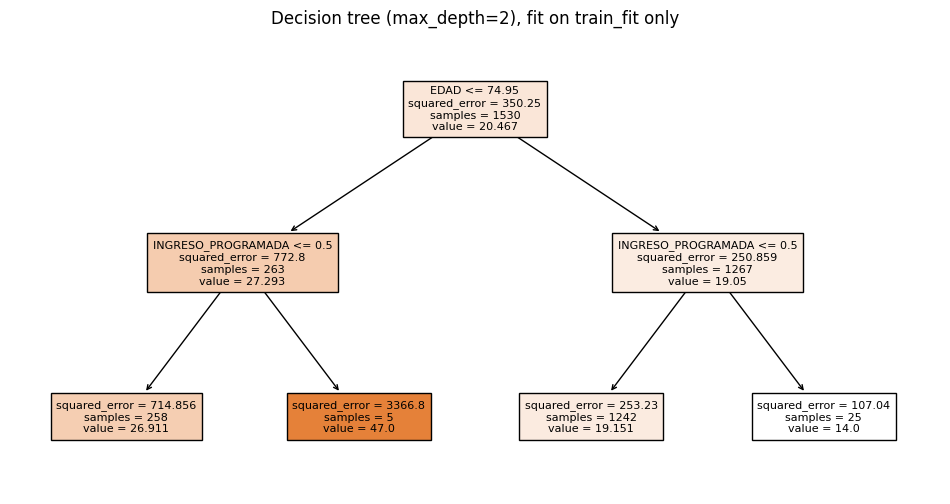

In [42]:
## Chosen setting (fill in once you see the comparison above): the depth with lowest validation MAE
chosen_depth = 2  # update based on the printed comparison
model = DecisionTreeRegressor(max_depth=chosen_depth, random_state=0)
model.fit(X_train_fit, y_train_fit)

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(model, feature_names=feature_cols, filled=True, fontsize=8, ax=ax)
plt.title(f'Decision tree (max_depth={chosen_depth}), fit on train_fit only')
plt.show()

### 13. Evaluate baseline and model on test (the only time test is used)

In [43]:

test_pred_model = model.predict(X_test)
test_mae_model = (y_test - test_pred_model).abs().mean()
test_mae_baseline = (y_test - baseline_pred).abs().mean()

print(f'Baseline MAE on test: {test_mae_baseline:.2f} days')
print(f'Model MAE on test:    {test_mae_model:.2f} days')

Baseline MAE on test: 8.93 days
Model MAE on test:    11.27 days


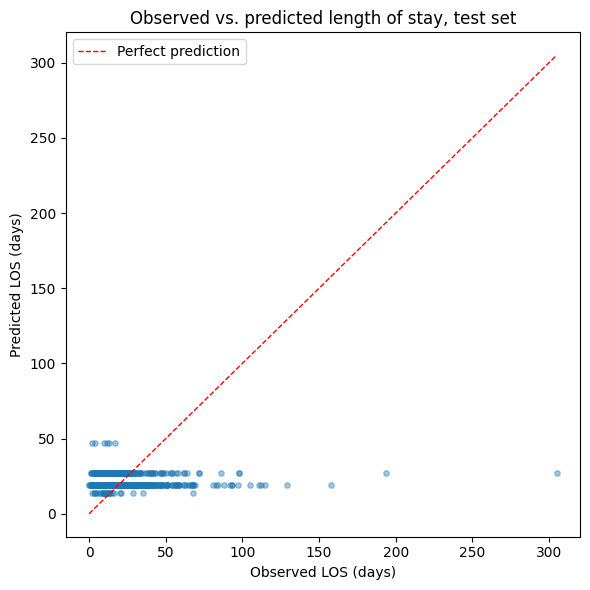

In [44]:
## Required plot: observed vs predicted
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_pred_model, alpha=0.4, s=15)
lims = [0, max(y_test.max(), test_pred_model.max())]
ax.plot(lims, lims, 'r--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Observed LOS (days)')
ax.set_ylabel('Predicted LOS (days)')
ax.set_title('Observed vs. predicted length of stay, test set')
ax.legend()
plt.tight_layout()
plt.show()

### 14. Log-transformed target

In [45]:
# log1p handles DIAS_ESTANCIA = 0 safely (log(0) is undefined, log1p(0) = 0)
y_train_fit_log = np.log1p(y_train_fit)
y_train_val_log = np.log1p(y_train_val)
y_test_log = np.log1p(y_test)

### 14.1 Baseline, in log-space (train-fit median, same discipline as before)

In [49]:
baseline_log = y_train_fit_log.median()
baseline_days = np.expm1(baseline_log)
print('Baseline (median LOS, from log-median):', round(baseline_days, 2), 'days')

baseline_val_mae_log = (y_train_val - np.expm1(baseline_log)).abs().mean()
print('Baseline MAE on validation (days):', round(baseline_val_mae_log, 2))

Baseline (median LOS, from log-median): 15.0 days
Baseline MAE on validation (days): 11.75


### 14.2 Model, trained on log target, compared on validation (same depth sweep as before)

In [50]:
for depth in [2, 3, 4]:
    m = DecisionTreeRegressor(max_depth=depth, random_state=0)
    m.fit(X_train_fit, y_train_fit_log)
    pred_val_days = np.expm1(m.predict(X_train_val))   # back-transform before measuring error
    val_mae = (y_train_val - pred_val_days).abs().mean()
    print(f'max_depth={depth} -> validation MAE (days): {val_mae:.2f}')

max_depth=2 -> validation MAE (days): 11.87
max_depth=3 -> validation MAE (days): 11.85
max_depth=4 -> validation MAE (days): 11.87


### 14.3 Final test evaluation, chosen depth from the comparison above

In [51]:
chosen_depth_log = 2  # update based on the printed comparison
model_log = DecisionTreeRegressor(max_depth=chosen_depth_log, random_state=0)
model_log.fit(X_train_fit, y_train_fit_log)

test_pred_log_days = np.expm1(model_log.predict(X_test))
test_mae_log_model = (y_test - test_pred_log_days).abs().mean()
test_mae_baseline = (y_test - baseline_days).abs().mean()

print(f'Baseline MAE on test (days):        {test_mae_baseline:.2f}')
print(f'Log-target model MAE on test (days): {test_mae_log_model:.2f}')

Baseline MAE on test (days):        8.93
Log-target model MAE on test (days): 9.22


### 14.4 Observed vs predicted, log-target model (back-transformed to days for readability)

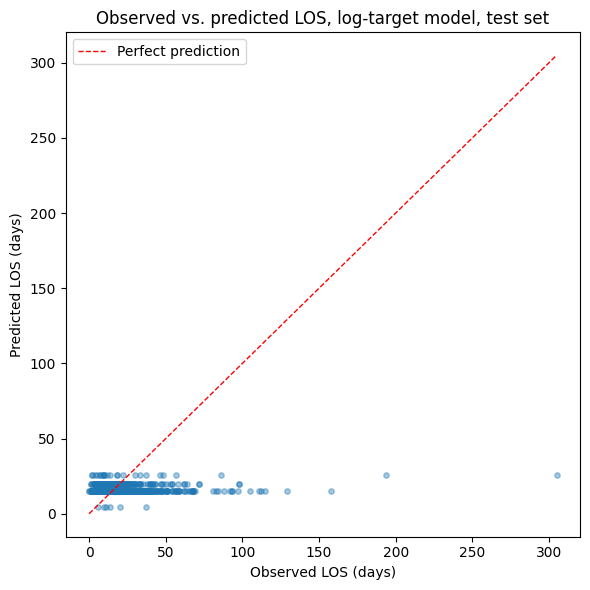

In [52]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_pred_log_days, alpha=0.4, s=15)
lims = [0, max(y_test.max(), test_pred_log_days.max())]
ax.plot(lims, lims, 'r--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Observed LOS (days)')
ax.set_ylabel('Predicted LOS (days)')
ax.set_title('Observed vs. predicted LOS, log-target model, test set')
ax.legend()
plt.tight_layout()
plt.show()

### 14.5 Tree structure, for the same interpretability check as before

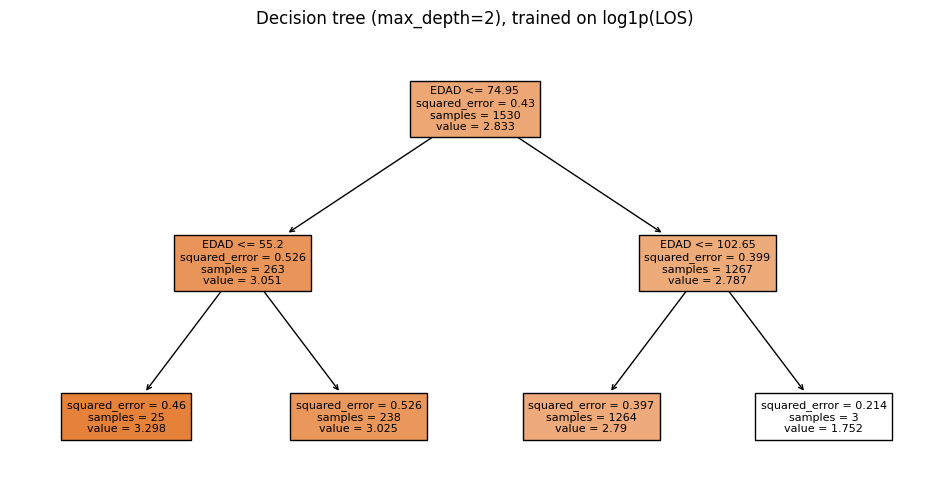

In [54]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(model_log, feature_names=feature_cols, filled=True, fontsize=8, ax=ax)
plt.title(f'Decision tree (max_depth={chosen_depth_log}), trained on log1p(LOS)')
plt.show()

In [62]:
from sklearn.metrics import classification_report, confusion_matrix
#%pip install lightgbm
from lightgbm import LGBMClassifier
# 1. Clean feature column names (removes LightGBM whitespace warnings)
X_train_fit.columns = [c.replace(' ', '_') for c in X_train_fit.columns]
X_train_val.columns = [c.replace(' ', '_') for c in X_train_val.columns]
X_test.columns = [c.replace(' ', '_') for c in X_test.columns]

# 2. Re-frame Target into Clinical Categories
bins = [-np.inf, 7, 15, np.inf]
labels = [0, 1, 2]
label_names = ['Short (<=7d)', 'Medium (8-15d)', 'Extended (>15d)']

y_train_fit_cat = pd.cut(y_train_fit, bins=bins, labels=labels).astype(int)
y_train_val_cat = pd.cut(y_train_val, bins=bins, labels=labels).astype(int)
y_test_cat = pd.cut(y_test, bins=bins, labels=labels).astype(int)

# 3. Train Classifier
clf = LGBMClassifier(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=0,
    verbose=-1
)

clf.fit(
    X_train_fit, 
    y_train_fit_cat,
    eval_set=[(X_train_val, y_train_val_cat)]
)

# 4. Evaluate & Predict
y_test_pred = clf.predict(X_test)
y_test_probs = clf.predict_proba(X_test)

print("--- Classification Report (Test Set) ---")
print(classification_report(y_test_cat, y_test_pred, target_names=label_names))

# Safe Probability Mapping
prob_df = pd.DataFrame(y_test_probs, columns=[label_names[c] for c in clf.classes_])
prob_df['Predicted_Class'] = [label_names[i] for i in y_test_pred]
prob_df['Actual_Class'] = y_test_cat.map(dict(zip(labels, label_names))).values

print("\nSample Probability Output:")
print(prob_df.head(5))

--- Classification Report (Test Set) ---
                 precision    recall  f1-score   support

   Short (<=7d)       0.24      0.34      0.28       477
 Medium (8-15d)       0.40      0.32      0.36       773
Extended (>15d)       0.36      0.32      0.34       667

       accuracy                           0.33      1917
      macro avg       0.33      0.33      0.33      1917
   weighted avg       0.34      0.33      0.33      1917


Sample Probability Output:
   Short (<=7d)  Medium (8-15d)  Extended (>15d)  Predicted_Class  \
0      0.397250        0.363868         0.238882     Short (<=7d)   
1      0.495575        0.327209         0.177216     Short (<=7d)   
2      0.408720        0.261740         0.329540     Short (<=7d)   
3      0.351838        0.357730         0.290432   Medium (8-15d)   
4      0.302339        0.345308         0.352353  Extended (>15d)   

      Actual_Class  
0     Short (<=7d)  
1  Extended (>15d)  
2   Medium (8-15d)  
3   Medium (8-15d)  
4  Extend

/opt/anaconda3/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [63]:
# 1. Update feature list to include Charlson Index
feature_cols = ['EDAD', 'INDICE_CHARLSON'] + [c for c in train_fit.columns if c.startswith('INGRESO_')]

# Clean column names for LightGBM compatibility
X_train_fit = train_fit[feature_cols].copy()
X_train_val = train_val[feature_cols].copy()
X_test = test[feature_cols].copy()

for df in [X_train_fit, X_train_val, X_test]:
    df.columns = [c.replace(' ', '_') for c in df.columns]

# 2. Define Binary Target: Prolonged Stay (>15 days)
CUTOFF_DAYS = 15
y_train_fit_bin = (train_fit['DIAS_ESTANCIA'] > CUTOFF_DAYS).astype(int)
y_train_val_bin = (train_val['DIAS_ESTANCIA'] > CUTOFF_DAYS).astype(int)
y_test_bin = (test['DIAS_ESTANCIA'] > CUTOFF_DAYS).astype(int)

# 3. Train LightGBM Binary Classifier
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, roc_auc_score

clf = LGBMClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=0,
    verbose=-1
)

clf.fit(
    X_train_fit, 
    y_train_fit_bin,
    eval_set=[(X_train_val, y_train_val_bin)]
)

# 4. Evaluate ROC-AUC and Classification Output
test_probs = clf.predict_proba(X_test)[:, 1]
test_preds = clf.predict(X_test)

print(f"Test ROC-AUC Score: {roc_auc_score(y_test_bin, test_probs):.3f}")
print("\n--- Classification Report (Prolonged Stay > 15 Days) ---")
print(classification_report(y_test_bin, test_preds, target_names=['<=15 Days', '>15 Days']))

Test ROC-AUC Score: 0.536

--- Classification Report (Prolonged Stay > 15 Days) ---
              precision    recall  f1-score   support

   <=15 Days       0.67      0.61      0.64      1250
    >15 Days       0.38      0.45      0.41       667

    accuracy                           0.55      1917
   macro avg       0.53      0.53      0.52      1917
weighted avg       0.57      0.55      0.56      1917



/opt/anaconda3/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [69]:

from sklearn.metrics import roc_auc_score
def engineer_admission_features(df):
    df = df.copy()
    
    # 1. Geographical features
    df['MISMA_COMUNA'] = (df['COMUNA_REGISTRADA'] == df['COMUNA_ESTAB']).astype(int)
    
    # 2. Fracture Subtype (ICD-10 category)
    df['ICD_SUBTYPE'] = df['DIAGNOSTICO1'].astype(str).str[:4]
    
    # 3. Comorbidity interaction
    df['AGE_COMORB_MULT'] = df['EDAD'] * df['N_COMORBILIDADES']
    
    # Convert text columns to category for LightGBM
    cat_cols = ['COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE']
    for col in cat_cols:
        if col in df.columns:
            df[col] = df[col].astype('category')
            
    return df

# Apply feature engineering across splits
train_fit_eng = engineer_admission_features(train_fit)
train_val_eng = engineer_admission_features(train_val)
test_eng = engineer_admission_features(test)

# Define feature columns (all guaranteed admission-safe)
admission_features = [
    'EDAD', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 
    'MISMA_COMUNA', 'COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE', 'AGE_COMORB_MULT'
] + [c for c in train_fit_eng.columns if c.startswith('INGRESO_')]

X_train_fit = train_fit_eng[admission_features]
X_train_val = train_val_eng[admission_features]
X_test = test_eng[admission_features]

### Run engineered feature pipeline

In [70]:
def prepare_features(df):
    df = df.copy()
    
    # 1. Geographical features
    df['MISMA_COMUNA'] = (df['COMUNA_REGISTRADA'] == df['COMUNA_ESTAB']).astype(int)
    
    # 2. Extract 4-character ICD-10 fracture subtype
    df['ICD_SUBTYPE'] = df['DIAGNOSTICO1'].astype(str).str[:4]
    
    # 3. Clinical risk interactions
    df['AGE_COMORB_MULT'] = df['EDAD'] * df['N_COMORBILIDADES']
    df['CHARLSON_AGE_MULT'] = df['EDAD'] * df['INDICE_CHARLSON']
    
    # Convert string columns to categorical for tree models
    for col in ['COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE']:
        if col in df.columns:
            df[col] = df[col].astype('category')
            
    return df

# Transform datasets
train_fit_eng = prepare_features(train_fit)
train_val_eng = prepare_features(train_val)
test_eng = prepare_features(test)

# Select all safe admission-time features
feature_cols = [
    'EDAD', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 
    'MISMA_COMUNA', 'COMUNA_REGISTRADA', 'COMUNA_ESTAB', 
    'ICD_SUBTYPE', 'AGE_COMORB_MULT', 'CHARLSON_AGE_MULT'
] + [c for c in train_fit_eng.columns if c.startswith('INGRESO_')]

# Clean column names (removes LightGBM whitespace warnings)
X_train_fit = train_fit_eng[feature_cols].copy()
X_train_val = train_val_eng[feature_cols].copy()
X_test = test_eng[feature_cols].copy()

for df_split in [X_train_fit, X_train_val, X_test]:
    df_split.columns = [c.replace(' ', '_') for c in df_split.columns]

### Test Alternative Baseline Models

In [74]:
# Binary target definition (>15 days)
y_train_fit_bin = (train_fit['DIAS_ESTANCIA'] > 15).astype(int)
y_train_val_bin = (train_val['DIAS_ESTANCIA'] > 15).astype(int)
y_test_bin = (test['DIAS_ESTANCIA'] > 15).astype(int)

# ---------------------------------------------------------
# A. LightGBM (Gradient Boosted Trees)
# ---------------------------------------------------------
lgb = LGBMClassifier(n_estimators=100, max_depth=3, learning_rate=0.03, class_weight='balanced', random_state=0, verbose=-1)
lgb.fit(X_train_fit, y_train_fit_bin)
lgb_auc = roc_auc_score(y_test_bin, lgb.predict_proba(X_test)[:, 1])

# ---------------------------------------------------------
# B. CatBoost (Optimal for high-cardinality communes & ICD codes)
# ---------------------------------------------------------
#%pip install catboost
from catboost import CatBoostClassifier


cat_features = ['COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE']
# Ensure categorical nulls are converted to strings for CatBoost
X_train_fit_cb = X_train_fit.copy()
X_test_cb = X_test.copy()
for col in cat_features:
    X_train_fit_cb[col] = X_train_fit_cb[col].astype(str)
    X_test_cb[col] = X_test_cb[col].astype(str)

cb = CatBoostClassifier(iterations=200, depth=4, auto_class_weights='Balanced', cat_features=cat_features, verbose=0, random_seed=0)
cb.fit(X_train_fit_cb, y_train_fit_bin)
cb_auc = roc_auc_score(y_test_bin, cb.predict_proba(X_test_cb)[:, 1])

# ---------------------------------------------------------
# C. Tweedie / Gamma Regressor (Continuous LOS framing)
# ---------------------------------------------------------
from sklearn.linear_model import TweedieRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numeric pipeline for continuous prediction using Gamma GLM
num_cols = ['EDAD', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 'MISMA_COMUNA', 'AGE_COMORB_MULT', 'CHARLSON_AGE_MULT']
preprocessor = ColumnTransformer([('num', 'passthrough', num_cols)])

glm_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', TweedieRegressor(power=2, max_iter=500))  # power=2 specifies Gamma distribution
])
glm_pipeline.fit(X_train_fit, train_fit['DIAS_ESTANCIA'])
glm_preds = glm_pipeline.predict(X_test)
glm_auc = roc_auc_score(y_test_bin, glm_preds)

print(f"Test ROC-AUC Comparison:")
print(f"  LightGBM: {lgb_auc:.3f}")
print(f"  CatBoost: {cb_auc:.3f}")
print(f"  Gamma GLM: {glm_auc:.3f}")

Test ROC-AUC Comparison:
  LightGBM: 0.699
  CatBoost: 0.720
  Gamma GLM: 0.616


In [ ]:
from sklearn.linear_model import LogisticRegression
import numpy as np

# 1. Get CatBoost predicted probabilities on train_val and test sets
X_train_val_cb = X_train_val.copy()
for col in cat_features:
    X_train_val_cb[col] = X_train_val_cb[col].astype(str)

cat_val_probs = cb.predict_proba(X_train_val_cb)[:, 1].reshape(-1, 1)
cat_test_probs = cb.predict_proba(X_test_cb)[:, 1].reshape(-1, 1)

# 2. Extract numeric features from train_val and test
X_val_num = X_train_val[['EDAD', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 'MISMA_COMUNA']].values
X_test_num = X_test[['EDAD', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 'MISMA_COMUNA']].values

# 3. Stack features: CatBoost probability + raw numeric features
X_val_stacked = np.hstack([cat_val_probs, X_val_num])
X_test_stacked = np.hstack([cat_test_probs, X_test_num])

# 4. Fit Logistic Regression meta-model
meta_model = LogisticRegression(class_weight='balanced')
meta_model.fit(X_val_stacked, y_train_val_bin)

# 5. Evaluate stacked model predictions
stacked_test_probs = meta_model.predict_proba(X_test_stacked)[:, 1]
print(f"Stacked (CatBoost + Logistic Regression) Test ROC-AUC: {roc_auc_score(y_test_bin, stacked_test_probs):.3f}")

NameError: name 'X_val_lr' is not defined

In [97]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

# Function for Out-of-Fold (OOF) Target Encoding
def target_encode_oof(train_df, test_df, target_series, cat_cols, n_splits=5, smoothing=10):
    global_mean = target_series.mean()
    train_encoded = train_df.copy()
    test_encoded = test_df.copy()
    
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    for col in cat_cols:
        col_te = col + '_TE'
        train_encoded[col_te] = np.nan
        
        # Out-of-Fold calculation for training set
        for train_idx, val_idx in skf.split(train_df, target_series):
            tr_sub = train_df.iloc[train_idx]
            target_sub = target_series.iloc[train_idx]
            
            stats = target_sub.groupby(tr_sub[col]).agg(['count', 'mean'])
            smooth_map = (stats['count'] * stats['mean'] + smoothing * global_mean) / (stats['count'] + smoothing)
            
            train_encoded.iloc[val_idx, train_encoded.columns.get_loc(col_te)] = (
                train_df.iloc[val_idx][col].map(smooth_map).fillna(global_mean)
            )
        
        # Encoding test set using full training data statistics
        full_stats = target_series.groupby(train_df[col]).agg(['count', 'mean'])
        full_smooth_map = (full_stats['count'] * full_stats['mean'] + smoothing * global_mean) / (full_stats['count'] + smoothing)
        test_encoded[col_te] = test_df[col].map(full_smooth_map).fillna(global_mean)
        
    return train_encoded, test_encoded

# 1. Apply Target Encoding
cat_cols = ['COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE']
num_cols = ['EDAD', 'INDICE_CHARLSON', 'N_COMORBILIDADES', 'MISMA_COMUNA', 'AGE_COMORB_MULT', 'CHARLSON_AGE_MULT']

train_encoded, test_encoded = target_encode_oof(
    X_train_fit_cb, X_test_cb, y_train_fit_bin, cat_cols=cat_cols
)

feature_cols = [c + '_TE' for c in cat_cols] + num_cols

X_train_lr = train_encoded[feature_cols]
X_test_lr = test_encoded[feature_cols]

# 2. Fit Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=0))
])

lr_pipeline.fit(X_train_lr, y_train_fit_bin)

# 3. Evaluate ROC-AUC Score
lr_probs = lr_pipeline.predict_proba(X_test_lr)[:, 1]
print(f"Linear (Logistic) Regression ROC-AUC: {roc_auc_score(y_test_bin, lr_probs):.3f}")

Linear (Logistic) Regression ROC-AUC: 0.719


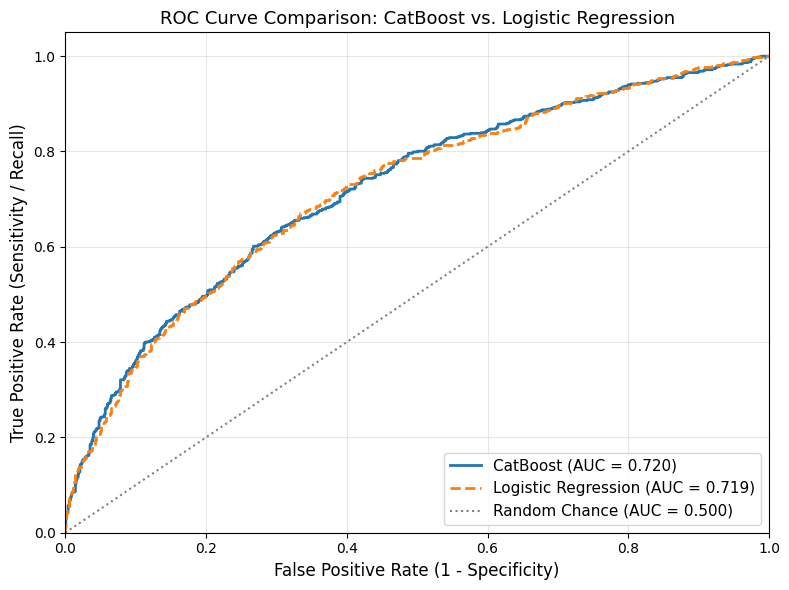

In [100]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Get predicted probabilities from both models on the test set
# (Assumes lr_pipeline was fit using the target-encoded features from the previous step)
cb_probs = cb.predict_proba(X_test_cb)[:, 1]
lr_probs = lr_pipeline.predict_proba(X_test_lr)[:, 1]

# 2. Compute ROC curves
fpr_cb, tpr_cb, _ = roc_curve(y_test_bin, cb_probs)
fpr_lr, tpr_lr, _ = roc_curve(y_test_bin, lr_probs)

auc_cb = roc_auc_score(y_test_bin, cb_probs)
auc_lr = roc_auc_score(y_test_bin, lr_probs)

# 3. Plot ROC Curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_cb, tpr_cb, color='#1f77b4', lw=2, label=f'CatBoost (AUC = {auc_cb:.3f})')
plt.plot(fpr_lr, tpr_lr, color='#ff7f0e', lw=2, linestyle='--', label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random Chance (AUC = 0.500)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('ROC Curve Comparison: CatBoost vs. Logistic Regression', fontsize=13)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

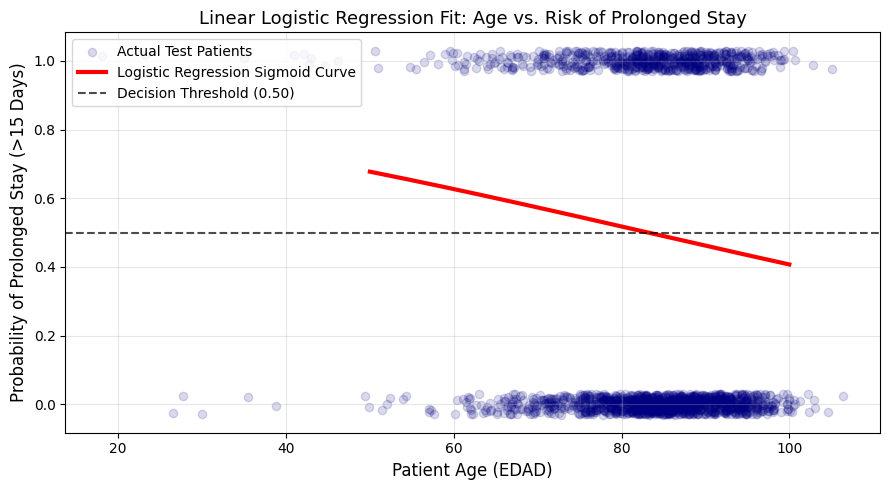

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# Fit a simple 1D Logistic Regression on Age alone for visualization
lr_age = LogisticRegression(class_weight='balanced')
X_age = X_train_fit[['EDAD']].values
lr_age.fit(X_age, y_train_fit_bin)

# Generate smooth sequence of ages from 50 to 100
age_grid = np.linspace(50, 100, 300).reshape(-1, 1)
prob_grid = lr_age.predict_proba(age_grid)[:, 1]

# Plot curve
plt.figure(figsize=(9, 5))

# Scatter actual test points (0 = <=15d, 1 = >15d) with jitter
plt.scatter(
    X_test['EDAD'], 
    y_test_bin + np.random.uniform(-0.03, 0.03, size=len(y_test_bin)), 
    alpha=0.15, color='navy', label='Actual Test Patients'
)

# Plot logistic regression sigmoid curve
plt.plot(age_grid, prob_grid, color='red', linewidth=3, label='Logistic Regression Sigmoid Curve')
plt.axhline(0.5, color='black', linestyle='--', alpha=0.7, label='Decision Threshold (0.50)')

plt.xlabel('Patient Age (EDAD)', fontsize=12)
plt.ylabel('Probability of Prolonged Stay (>15 Days)', fontsize=12)
plt.title('Linear Logistic Regression Fit: Age vs. Risk of Prolonged Stay', fontsize=13)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Feature Importance analysis

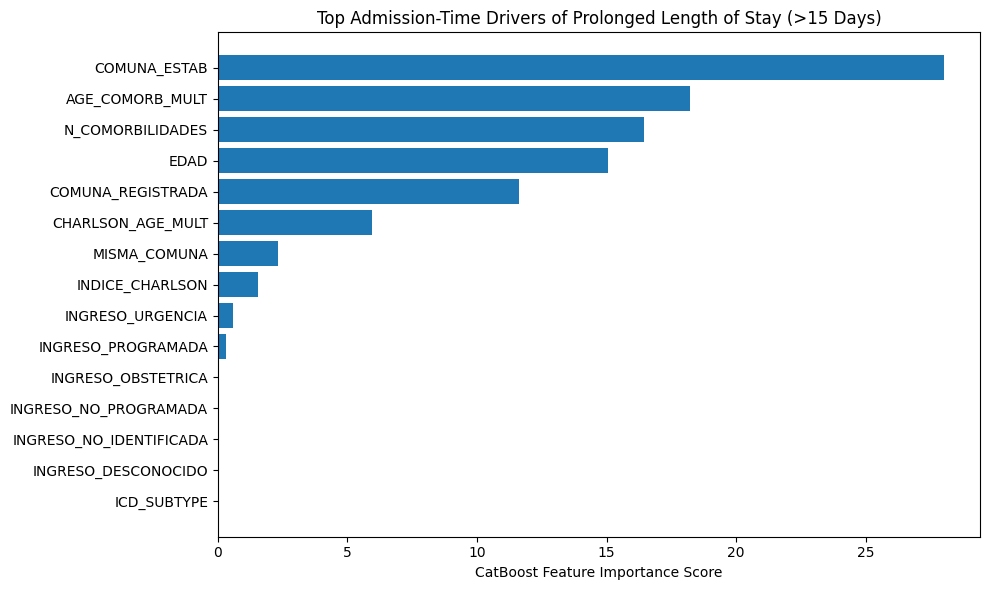

In [75]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from CatBoost
feature_importances = cb.get_feature_importance()
feature_names = X_train_fit_cb.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=True)

# Plot top features
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='#1f77b4')
plt.xlabel('CatBoost Feature Importance Score')
plt.title('Top Admission-Time Drivers of Prolonged Length of Stay (>15 Days)')
plt.tight_layout()
plt.show()

In [76]:
from sklearn.metrics import classification_report, confusion_matrix

# Test different probability thresholds
optimal_threshold = 0.42  # Adjust based on precision/recall needs
y_test_pred_custom = (cb.predict_proba(X_test_cb)[:, 1] >= optimal_threshold).astype(int)

print(f"--- Classification Report at Threshold {optimal_threshold} ---")
print(classification_report(y_test_bin, y_test_pred_custom, target_names=['<=15 Days', '>15 Days']))

--- Classification Report at Threshold 0.42 ---
              precision    recall  f1-score   support

   <=15 Days       0.83      0.41      0.55      1250
    >15 Days       0.43      0.84      0.57       667

    accuracy                           0.56      1917
   macro avg       0.63      0.62      0.56      1917
weighted avg       0.69      0.56      0.55      1917



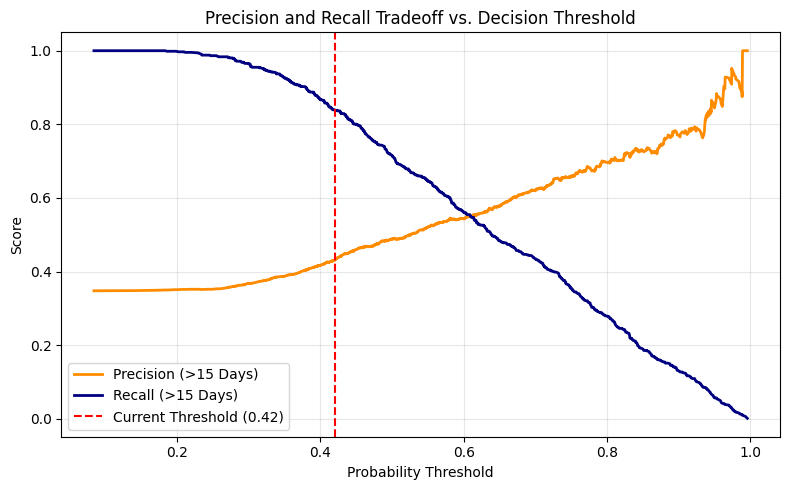

In [77]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall across all probability thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test_bin, cb.predict_proba(X_test_cb)[:, 1])

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision (>15 Days)', color='darkorange', lw=2)
plt.plot(thresholds, recalls[:-1], label='Recall (>15 Days)', color='navy', lw=2)
plt.axvline(x=0.42, color='red', linestyle='--', label='Current Threshold (0.42)')

plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall Tradeoff vs. Decision Threshold')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [78]:
import pandas as pd

# Group by patient commune and compute stay metrics
# Filter for communes with at least 10-15 patients to avoid small-sample distortion
commune_summary = (
    train_fit.groupby('COMUNA_REGISTRADA')
    .agg(
        total_patients=('DIAS_ESTANCIA', 'count'),
        median_los=('DIAS_ESTANCIA', 'median'),
        mean_los=('DIAS_ESTANCIA', 'mean'),
        prolonged_stay_pct=('DIAS_ESTANCIA', lambda x: (x > 15).mean() * 100)
    )
    .query('total_patients >= 10')
    .sort_values(by='median_los', ascending=False)
)

print("--- Top 10 Patient Communes by Highest Median Length of Stay ---")
print(commune_summary.head(10))

--- Top 10 Patient Communes by Highest Median Length of Stay ---
                   total_patients  median_los   mean_los  prolonged_stay_pct
COMUNA_REGISTRADA                                                           
VALPARAISO                     38        47.0  52.315789           94.736842
ANTOFAGASTA                    24        35.5  36.708333           87.500000
VALDIVIA                       17        27.0  41.647059           82.352941
LINARES                        10        26.5  38.700000           80.000000
SAN MIGUEL                     10        25.0  27.500000           80.000000
COQUIMBO                       19        22.0  31.947368           57.894737
LA SERENA                      10        21.5  32.200000           60.000000
NUNOA                          22        21.0  23.545455           72.727273
IQUIQUE                        16        20.5  20.125000           68.750000
PENALOLEN                      19        20.0  22.894737           68.421053


/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_85468/3637046239.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_fit.groupby('COMUNA_REGISTRADA')


In [79]:
transfer_summary = (
    train_fit_eng.groupby('MISMA_COMUNA')
    .agg(
        patient_count=('DIAS_ESTANCIA', 'count'),
        median_los=('DIAS_ESTANCIA', 'median'),
        mean_los=('DIAS_ESTANCIA', 'mean'),
        pct_prolonged=('DIAS_ESTANCIA', lambda x: (x > 15).mean() * 100)
    )
    .rename(index={1: 'Local (Same Commune)', 0: 'Out-of-District Transfer'})
)

print("\n--- Length of Stay: Local vs. Out-of-District Patients ---")
print(transfer_summary)


--- Length of Stay: Local vs. Out-of-District Patients ---
                          patient_count  median_los   mean_los  pct_prolonged
MISMA_COMUNA                                                                 
Out-of-District Transfer            774        15.0  19.356589      48.449612
Local (Same Commune)                756        16.0  21.603175      50.132275


In [82]:
#%pip install geopandas plotly
import geopandas as gpd
import plotly.express as px

# 1. Prepare commune-level summary dataframe from train_fit
commune_df = train_fit.groupby('COMUNA_REGISTRADA').agg(
    median_los=('DIAS_ESTANCIA', 'median'),
    prolonged_pct=('DIAS_ESTANCIA', lambda x: (x > 15).mean() * 100),
    total_patients=('DIAS_ESTANCIA', 'count')
).reset_index()

# 2. Plot interactive bar chart of top communes by median stay
fig = px.bar(
    commune_df.query('total_patients >= 10').sort_values('median_los', ascending=False).head(15),
    x='COMUNA_REGISTRADA',
    y='median_los',
    color='prolonged_pct',
    title='Median Length of Stay & % Prolonged Stay by Patient Origin Commune',
    labels={'median_los': 'Median LOS (Days)', 'prolonged_pct': '% Prolonged Stay (>15d)'},
    color_continuous_scale='Reds'
)
fig.show()

/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_85468/4281266363.py:6: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.8/114.8 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 1.9 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 9.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 8.9 MB/s eta 0:00:0000:0100:01m
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4031 sha256=e132ffcce7e1c358842a42cfe76c30150f7069399a4eeab264e2b1879f068b6b
  Stored in directory: /Users/maria/Library/Caches/pip/wheels/8b/67/f4/2caaae2146198dcb824f31a303833b07b14a5ec863fb3acd7b
Successfully built autograd-gamma
  Attempting uninstall: numpy
    Found existing ins

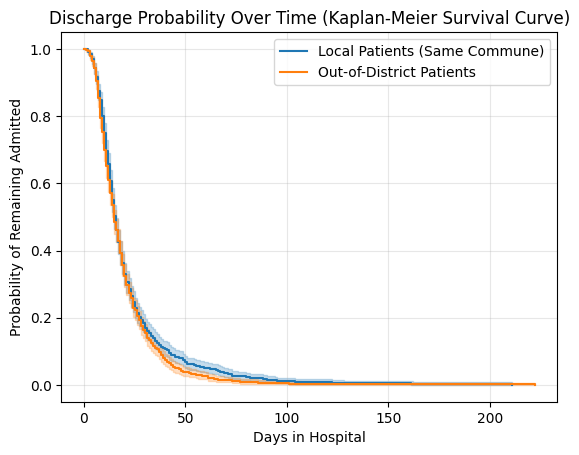

In [89]:
 %pip install lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter

# Fit Kaplan-Meier curve comparing Local vs. Out-of-District Patients
kmf = KaplanMeierFitter()
ax = plt.subplot(111)

# Group 1: Local patients
mask_local = (train_fit_eng['MISMA_COMUNA'] == 1)
kmf.fit(train_fit['DIAS_ESTANCIA'][mask_local], label='Local Patients (Same Commune)')
kmf.plot_survival_function(ax=ax)

# Group 2: Transfer / Out-of-district patients
kmf.fit(train_fit['DIAS_ESTANCIA'][~mask_local], label='Out-of-District Patients')
kmf.plot_survival_function(ax=ax)

plt.title('Discharge Probability Over Time (Kaplan-Meier Survival Curve)')
plt.xlabel('Days in Hospital')
plt.ylabel('Probability of Remaining Admitted')
plt.grid(True, alpha=0.3)
plt.show()

## AI use and verification

Prompt excerpt: "the commune-year check groups only by commune, but the report describes
checking commune-year — fix the code to match."
Claude's output: corrected groupby to `['COMUNA_ESTAB', 'YEAR']` (Section 6.1).
How checked: re-ran the cell and confirmed `key_by_estab_year` returns 1, consistent with
population being an annual figure, before accepting the fix.